# Lab 6 – RNNs for time-series forecasting and Bach chorale generation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

def generate_time_series(batch_size, n_steps):
    freq1, freq2, offsets1, offsets2 = np.random.rand(4, batch_size, 1)
    time = np.linspace(0, 1, n_steps)
    series = 0.5 * np.sin((time - offsets1) * (freq1 * 10 + 10))
    series += 0.2 * np.sin((time - offsets2) * (freq2 * 20 + 20))
    series += 0.1 * (np.random.rand(batch_size, n_steps) - 0.5)
    return series[..., np.newaxis].astype(np.float32)

n_steps = 50
series = generate_time_series(10000, n_steps + 10)

X_train, y_train = series[:7000, :n_steps], series[:7000, -10:, 0]
X_valid, y_valid = series[7000:9000, :n_steps], series[7000:9000, -10:, 0]
X_test, y_test = series[9000:, :n_steps], series[9000:, -10:, 0]

In [2]:
model_rnn = keras.models.Sequential([
    keras.layers.SimpleRNN(20, input_shape=[None, 1]),
    keras.layers.Dense(10)
])
model_rnn.compile(loss="mse", optimizer="adam")
history_rnn = model_rnn.fit(X_train, y_train, epochs=5, validation_data=(X_valid, y_valid))

model_deep_rnn = keras.models.Sequential([
    keras.layers.SimpleRNN(20, return_sequences=True, input_shape=[None, 1]),
    keras.layers.SimpleRNN(20),
    keras.layers.Dense(10)
])
model_deep_rnn.compile(loss="mse", optimizer="adam")
history_deep_rnn = model_deep_rnn.fit(X_train, y_train, epochs=5, validation_data=(X_valid, y_valid))

Epoch 1/5


219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0605 - val_loss: 0.0403
Epoch 2/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0370 - val_loss: 0.0320
Epoch 3/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0313 - val_loss: 0.0281
Epoch 4/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0263 - val_loss: 0.0227
Epoch 5/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0223 - val_loss: 0.0204
Epoch 1/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0574 - val_loss: 0.0306
Epoch 2/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0252 - val_loss: 0.0194
Epoch 3/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0172 - val_loss: 0.0136
Epoch 4/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0140 - val_loss: 0.0118
Epoch 5/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0126 - val_loss: 0.0109


In [3]:
model_norm_rnn = keras.models.Sequential([
    keras.layers.SimpleRNN(20, return_sequences=True, input_shape=[None, 1]),
    keras.layers.BatchNormalization(),
    keras.layers.LayerNormalization(),
    keras.layers.SimpleRNN(20),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(10)
])
model_norm_rnn.compile(loss="mse", optimizer="adam")
history_norm_rnn = model_norm_rnn.fit(X_train, y_train, epochs=5, validation_data=(X_valid, y_valid))

Epoch 1/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2421 - val_loss: 0.1016
Epoch 2/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0599 - val_loss: 0.0485
Epoch 3/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0451 - val_loss: 0.0510
Epoch 4/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0373 - val_loss: 0.0341
Epoch 5/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0330 - val_loss: 0.0267


In [4]:
model_lstm = keras.models.Sequential([
    keras.layers.LSTM(20, return_sequences=True, input_shape=[None, 1]),
    keras.layers.LSTM(20),
    keras.layers.Dense(10)
])
model_lstm.compile(loss="mse", optimizer="adam")
history_lstm = model_lstm.fit(X_train, y_train, epochs=5, validation_data=(X_valid, y_valid))

model_gru = keras.models.Sequential([
    keras.layers.GRU(20, return_sequences=True, input_shape=[None, 1]),
    keras.layers.GRU(20),
    keras.layers.Dense(10)
])
model_gru.compile(loss="mse", optimizer="adam")
history_gru = model_gru.fit(X_train, y_train, epochs=5, validation_data=(X_valid, y_valid))

Epoch 1/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0626 - val_loss: 0.0348
Epoch 2/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0281 - val_loss: 0.0238
Epoch 3/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0211 - val_loss: 0.0188
Epoch 4/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0182 - val_loss: 0.0163
Epoch 5/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0164 - val_loss: 0.0150
Epoch 1/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0730 - val_loss: 0.0445
Epoch 2/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0402 - val_loss: 0.0357
Epoch 3/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0329 - val_loss: 0.0301
Epoch 4/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0286 - val_loss: 0.0258
Epoch 5/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0243 - val_loss: 0.0197


--- Test Set MSE ---
Simple RNN: 0.02086
Deep RNN: 0.01104
Norm RNN: 0.02736
LSTM: 0.01464
GRU: 0.01959


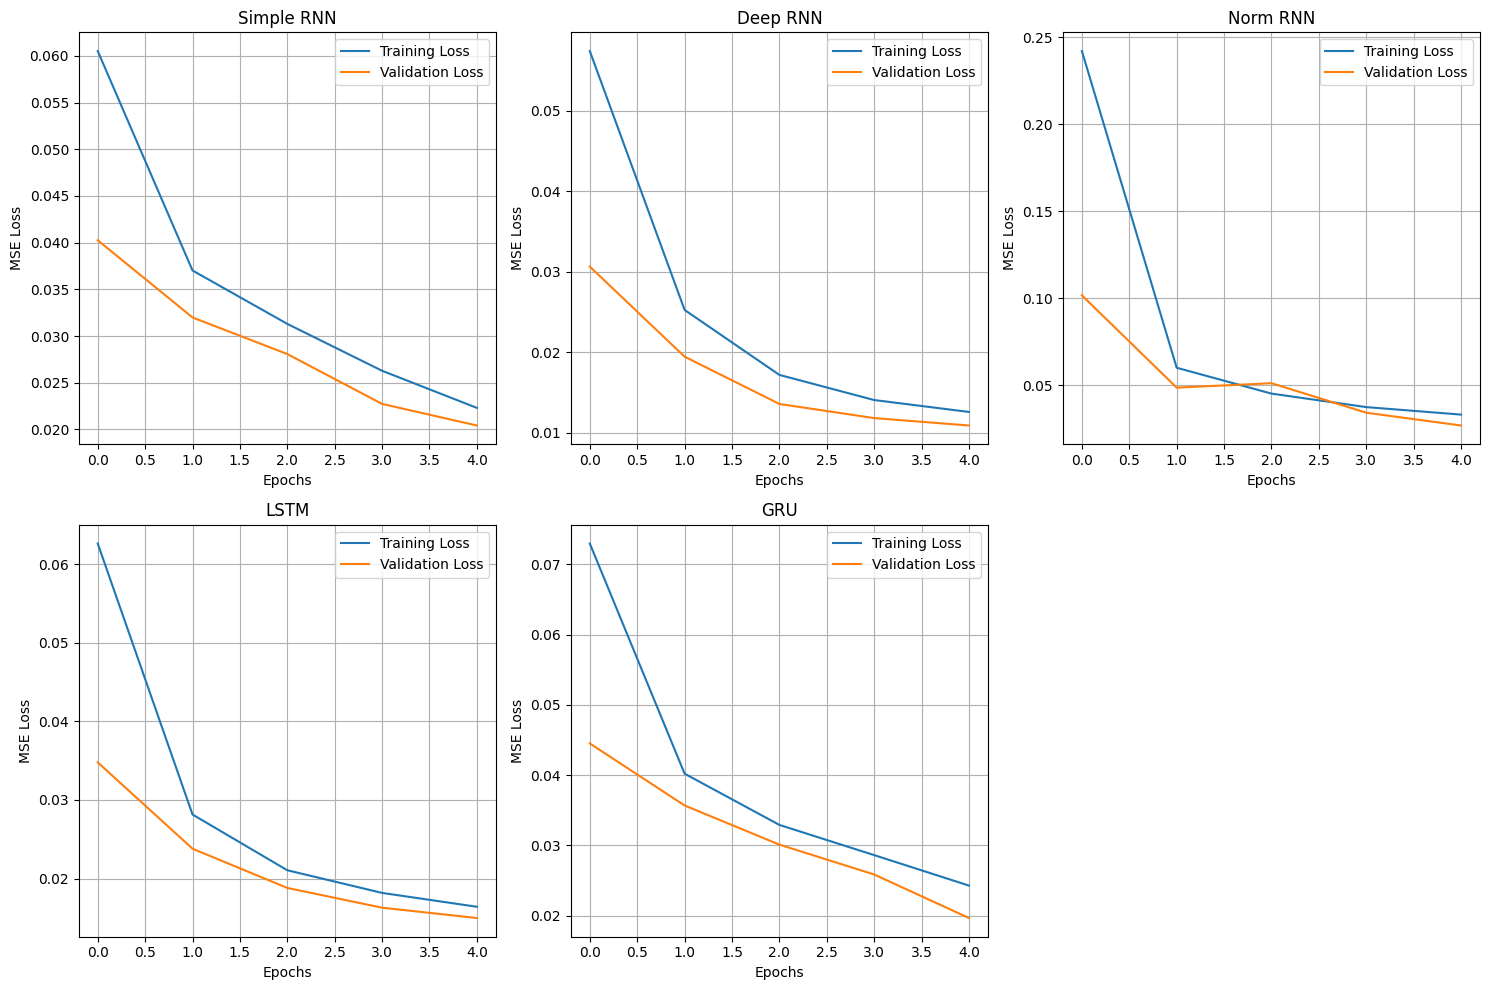

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step


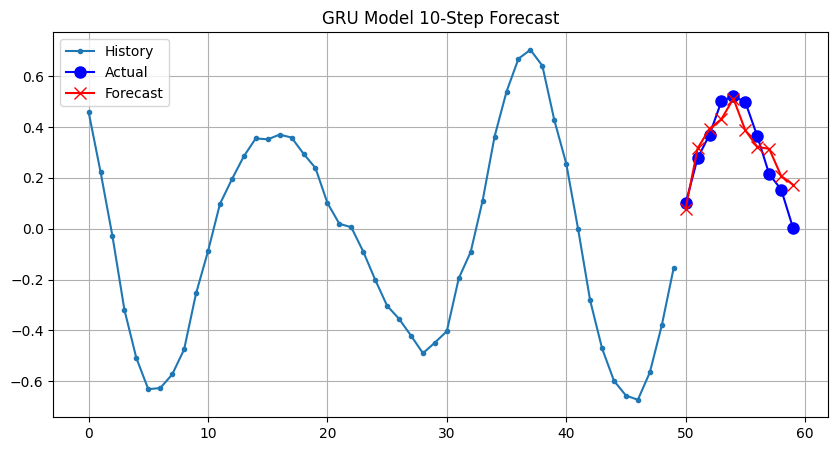

In [5]:
models = {
    "Simple RNN": model_rnn,
    "Deep RNN": model_deep_rnn,
    "Norm RNN": model_norm_rnn,
    "LSTM": model_lstm,
    "GRU": model_gru
}

print("--- Test Set MSE ---")
for name, model in models.items():
    mse = model.evaluate(X_test, y_test, verbose=0)
    print(f"{name}: {mse:.5f}")

def plot_learning_curves(history, title):
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('MSE Loss')
    plt.legend()
    plt.grid(True)

plt.figure(figsize=(15, 10))
histories = [history_rnn, history_deep_rnn, history_norm_rnn, history_lstm, history_gru]
names = list(models.keys())
for i in range(5):
    plt.subplot(2, 3, i+1)
    plot_learning_curves(histories[i], names[i])
plt.tight_layout()
plt.show()

def plot_multiple_forecasts(X, Y, Y_pred):
    n_steps = X.shape[1]
    ahead = Y.shape[1]
    plt.plot(np.arange(n_steps), X[0, :, 0], ".-", label="History")
    plt.plot(np.arange(n_steps, n_steps + ahead), Y[0, :], "bo-", label="Actual", markersize=8)
    plt.plot(np.arange(n_steps, n_steps + ahead), Y_pred[0, :], "rx-", label="Forecast", markersize=8)
    plt.legend()
    plt.grid(True)
    plt.show()

y_pred_gru = model_gru.predict(X_test[:1])
plt.figure(figsize=(10, 5))
plt.title("GRU Model 10-Step Forecast")
plot_multiple_forecasts(X_test[:1], y_test[:1], y_pred_gru)

In [6]:
import os
import tarfile
from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras

DOWNLOAD_ROOT = "https://github.com/ageron/data/raw/main/"
filepath = keras.utils.get_file("jsb_chorales.tgz", DOWNLOAD_ROOT + "jsb_chorales.tgz")
tarfile.open(filepath, 'r:gz').extractall(path=os.path.dirname(filepath))
jsb_chorales_dir = Path(os.path.dirname(filepath)) / "jsb_chorales"

def load_chorales(filepaths):
    return [pd.read_csv(filepath).values.tolist() for filepath in filepaths]

train_files = sorted(jsb_chorales_dir.glob("train/chorale_*.csv"))
valid_files = sorted(jsb_chorales_dir.glob("valid/chorale_*.csv"))
test_files = sorted(jsb_chorales_dir.glob("test/chorale_*.csv"))

train_chorales = load_chorales(train_files)
valid_chorales = load_chorales(valid_files)
test_chorales = load_chorales(test_files)

min_note = 36
max_note = 81
# +1 for the rest token (0) and an offset so note indices start at 1
vocab_size = max_note - min_note + 2 

def create_dataset(chorales, batch_size=32, shuffle_buffer_size=None, window_size=32, window_shift=16):
    def batch_window(window):
        return window.batch(window_size + 1)
    
    def to_dataset(chorale):
        dataset = tf.data.Dataset.from_tensor_slices(chorale)
        dataset = dataset.window(window_size + 1, shift=window_shift, drop_remainder=True)
        return dataset.flat_map(batch_window)

    # FIX: Convert non-rectangular list to a RaggedTensor
    ragged_chorales = tf.ragged.constant(chorales, ragged_rank=1)
    dataset = tf.data.Dataset.from_tensor_slices(ragged_chorales)
    dataset = dataset.flat_map(to_dataset)
    
    if shuffle_buffer_size:
        dataset = dataset.shuffle(shuffle_buffer_size)
        
    # FIX: Handle 0s (rests) safely so they don't become negative values
    def shift_notes(window):
        return tf.where(window == 0, window, window - min_note + 1)
        
    dataset = dataset.map(lambda window: (shift_notes(window[:-1]), shift_notes(window[1:])))
    dataset = dataset.batch(batch_size).prefetch(1)
    return dataset

train_set = create_dataset(train_chorales, shuffle_buffer_size=1000)
valid_set = create_dataset(valid_chorales)
test_set = create_dataset(test_chorales)

In [7]:
bach_model = keras.models.Sequential([
    keras.layers.LSTM(64, return_sequences=True, input_shape=[None, 4]),
    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.Dense(4 * vocab_size),
    keras.layers.Reshape((-1, 4, vocab_size)),
    keras.layers.Activation("softmax")
])

bach_model.compile(loss="sparse_categorical_crossentropy", optimizer="nadam", metrics=["accuracy"])
history_bach = bach_model.fit(train_set, epochs=50, validation_data=valid_set)

def generate_bach_music(model, seed_chords, length=50):
    arpeggio = list(seed_chords)
    for step in range(length):
        X = np.array(arpeggio)[np.newaxis, ...]
        X = np.where(X == 0, X, X - min_note + 1)
        
        y_proba = model.predict(X, verbose=0)[0, -1]
        
        new_chord = []
        for voice in range(4):
            note_index = np.argmax(y_proba[voice, :])
            note = 0 if note_index == 0 else note_index + min_note - 1
            new_chord.append(note)
        arpeggio.append(new_chord)
    return np.array(arpeggio)

seed = test_chorales[0][:8]
new_music = generate_bach_music(bach_model, seed, length=20)
print(new_music)

Epoch 1/50


     93/Unknown 3s 10ms/step - accuracy: 0.1060 - loss: 3.2090

98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.1365 - loss: 2.8402 - val_accuracy: 0.1509 - val_loss: 2.6258
Epoch 2/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1624 - loss: 2.5875 - val_accuracy: 0.1865 - val_loss: 2.5872
Epoch 3/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.2008 - loss: 2.4628 - val_accuracy: 0.2120 - val_loss: 2.4048
Epoch 4/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.2379 - loss: 2.3130 - val_accuracy: 0.2487 - val_loss: 2.3026
Epoch 5/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.2761 - loss: 2.2103 - val_accuracy: 0.2871 - val_loss: 2.2060
Epoch 6/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3126 - loss: 2.1173 - val_accuracy: 0.3147 - val_loss: 2.1183
Epoch 7/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3400 - loss: 2.0333 - val_accuracy: 0.3406 - val_loss: 2.0402
Epoch 8/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3626 - loss: 1.9663 - val_accuracy: 0.3572 - val_loss: 1.